# Supplementary Figure S14e. STRING network of inhibitory-neuron trans-eProgram 115

STRING (v12.5, *Homo sapiens*, combined score >= 0.4) network among the 156 genes of inhibitory-neuron Hotspot *trans*-eProgram 115. Red edges are pairs that also have evidence in STRING's physical-interaction network (physical proximity), grey edges functional association only. Only genes with at least one edge are drawn. No network file for this program was saved by the author, so the network was retrieved in the prep script with the same API calls and thresholds as the author's other STRING panels (`Figure6.ipynb` cell 35); retrieval date is in `ppi$retrieved`. The layout is a seeded Fruchterman-Reingold layout.

Input: `data/Figure_S14e_Inh_program115_PPI.rds`


In [1]:
library(ggplot2)
library(ggrepel)
ppi <- readRDS("data/Figure_S14e_Inh_program115_PPI.rds")
c(n_query_genes = ppi$n_query, n_nodes = nrow(ppi$nodes), n_edges = nrow(ppi$edges),
  n_unmapped = length(ppi$unmapped))
table(ppi$edges$type)
head(ppi$edges[order(-ppi$edges$functional_score), 1:5])

n_query_genes       n_nodes       n_edges    n_unmapped 
          156            71            72             0


Functional association only     Physical-proximity link 
                         42                          30 

,gene_a,gene_b,functional_score,physical_score,type
,<chr>,<chr>,<dbl>,<dbl>,<chr>
3,RFC2,RFC5,0.999,0.999,Physical-proximity link
12,EIF3K,EIF3J,0.999,0.999,Physical-proximity link
25,PRPF6,TXNL4A,0.999,0.999,Physical-proximity link
65,POLR3F,POLR3D,0.999,0.999,Physical-proximity link
24,PRPF6,MFAP1,0.998,0.989,Physical-proximity link
36,COQ5,COQ7,0.998,0.956,Physical-proximity link


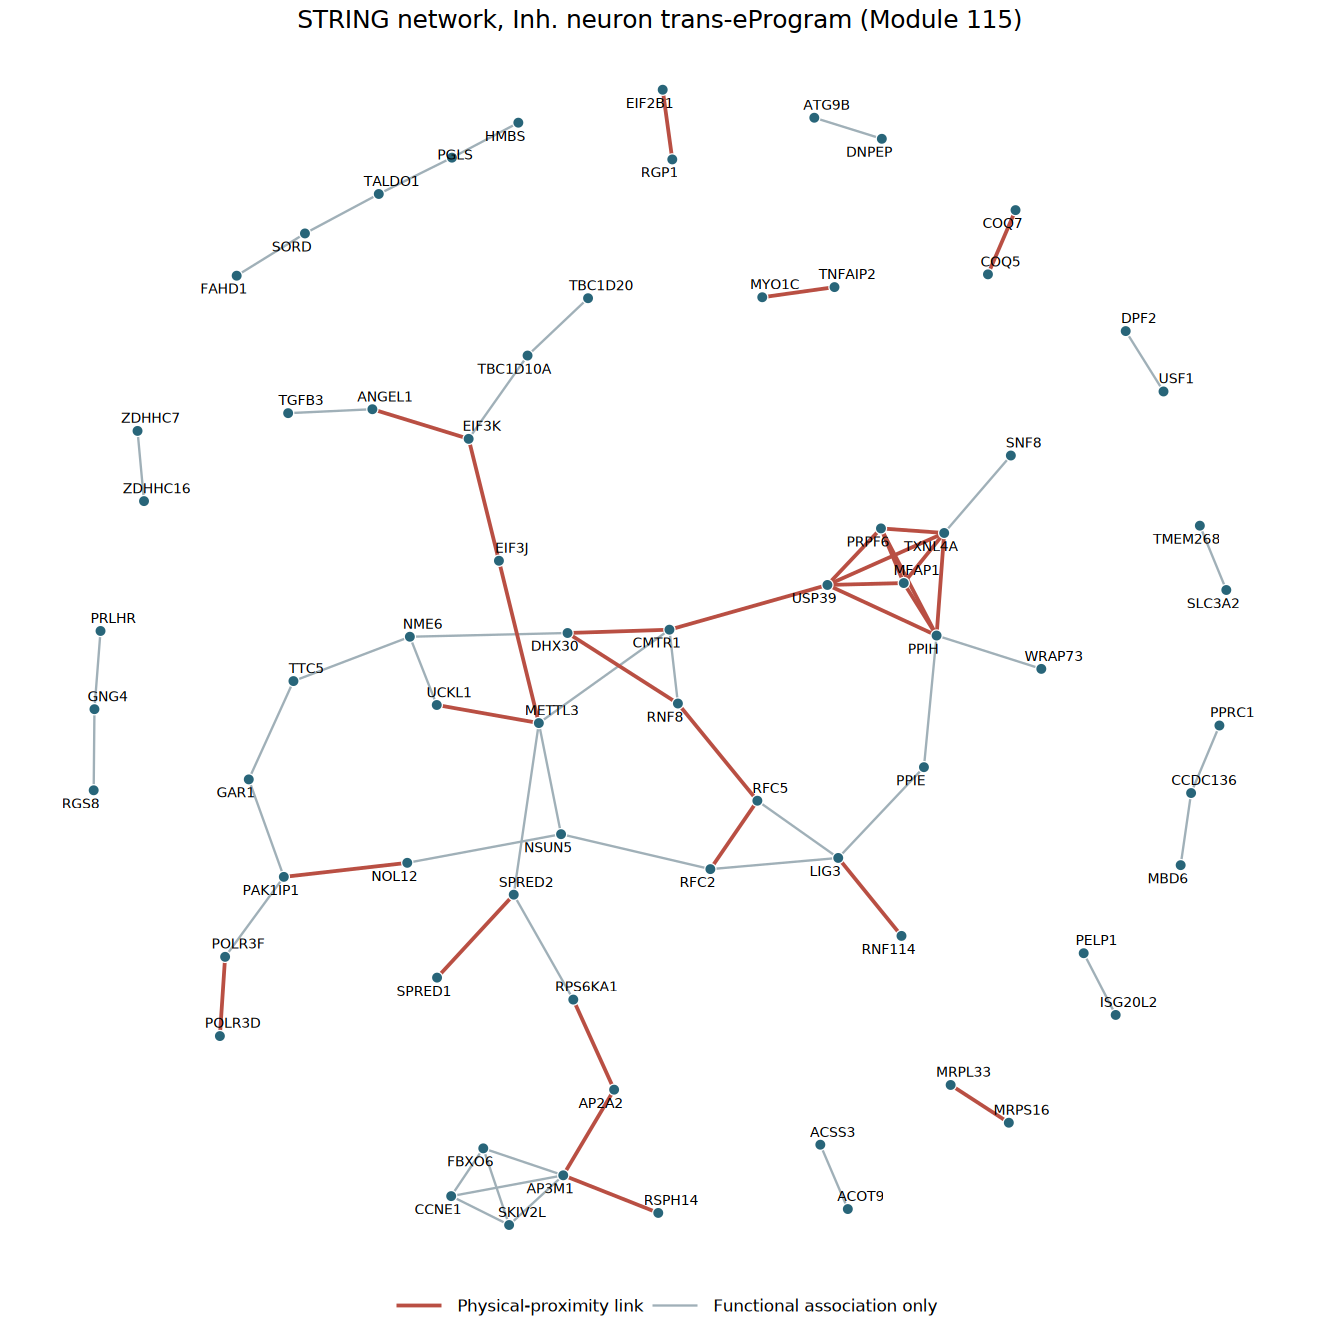

In [2]:
draw_network <- function(ppi, title, label_min_degree = 0, focal_col = "#C0392B") {
  edges <- ppi$edges; nodes <- ppi$nodes
  nodes$lab <- ifelse(nodes$degree >= label_min_degree | nodes$focal, nodes$gene, "")
  ggplot() +
    geom_segment(data = edges[edges$type == "Functional association only", ],
                 aes(x, y, xend = xend, yend = yend, colour = type), linewidth = 0.5) +
    geom_segment(data = edges[edges$type != "Functional association only", ],
                 aes(x, y, xend = xend, yend = yend, colour = type), linewidth = 0.8) +
    geom_point(data = nodes[!nodes$focal, ], aes(x, y), shape = 21, size = 2.6, fill = "#286579",
               colour = "white", stroke = 0.4) +
    geom_point(data = nodes[nodes$focal, ], aes(x, y), size = 4.5, colour = focal_col) +
    geom_text_repel(data = nodes, aes(x, y, label = lab), size = 2.8, fontface = "italic", seed = 1,
                    max.overlaps = Inf, min.segment.length = 0.3, segment.colour = "grey70",
                    segment.size = 0.25) +
    scale_colour_manual(values = c("Physical-proximity link" = "#B94F43",
                                   "Functional association only" = "#A0B0B8"),
                        limits = c("Physical-proximity link", "Functional association only"),
                        drop = FALSE, name = NULL) +
    labs(title = title) +
    coord_fixed() +
    theme_void(base_size = 12) +
    theme(plot.title = element_text(hjust = 0.5), legend.position = "bottom",
          legend.key.width = grid::unit(12, "mm"))
}

p <- draw_network(ppi, "STRING network, Inh. neuron trans-eProgram (Module 115)")
options(repr.plot.width = 11, repr.plot.height = 11)
p